# Analysis — all arms

Statistical analysis from proposal Bab III (3.6 Metrik Evaluasi, 3.7 Analisis Statistik), on the results in the private
dataset repo `dimsmauls/code4ml-eval-outputs`.

| RQ | Data | Method |
|---|---|---|
| RQ1, RQ3 structural | `<run>/code4ml_ratings.csv` (SonarQube + MLScent on the 304 Code4ML test answers) | Friedman (vanilla, few-shot, LoRA, QLoRA) → Wilcoxon signed-rank + Holm (5 comparisons); Kendall's W, rank-biserial r; 14B family (3 comparisons, own Holm); sensitivity on density per 100 `ncloc` |
| RQ3, RQ4 functional | `<run>/ds1000_results.jsonl` (DS-1000, 997 problems × 10 samples) | Cochran's Q → McNemar + Holm; paired bootstrap 95% CI of the difference in proportions |
| RQ2 | both | Arm-level comparison of structural quality and functional correctness |
| RQ4 | `refinement-<method>/seed-*/refinement_results.jsonl` | Cochran's Q over iterations → McNemar between consecutive iterations + Holm; bootstrap CI; saturation point |

Rules from the proposal: unit = the same prompt / problem in every arm; for LoRA and QLoRA the value per prompt is the
median of the 3 seeds (seed variation reported descriptively); only AST-valid code is rated; paired tests use complete
blocks only; alpha = 0.05.

**Colab:** add a Hugging Face token with read access as the secret `HF_TOKEN` (key icon on the left), then Run all.
`code4ml_ratings.csv` comes from `rating/rate_outputs.ipynb`; run that first.

## 1. Setup

In [29]:
%pip install -q pandas scipy statsmodels huggingface_hub matplotlib   # into the selected kernel (Colab or local)



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
import os

try:  # Colab secret; elsewhere an existing `hf auth login` is used
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

import json
from collections import Counter

import numpy as np
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from scipy import stats
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

REPO = "dimsmauls/code4ml-eval-outputs"
SEEDS = (42, 43, 44)
RUNS = {"vanilla": ["vanilla"], "few-shot": ["few-shot"], "qwen-14b": ["qwen-14b"],
        "lora": [f"lora/seed-{s}" for s in SEEDS], "qlora": [f"qlora/seed-{s}" for s in SEEDS]}
FRIEDMAN_ARMS = ["vanilla", "few-shot", "lora", "qlora"]
MAIN_FAMILY = [("lora", "vanilla"), ("qlora", "vanilla"), ("lora", "few-shot"), ("qlora", "few-shot"), ("lora", "qlora")]
FAMILY_14B = [("qwen-14b", "lora"), ("qwen-14b", "qlora"), ("qwen-14b", "vanilla")]
ALPHA = 0.05
BOOTSTRAP = 10_000
SEED = 42

files = set(HfApi().list_repo_files(REPO, repo_type="dataset"))
missing = [f"{run}/{name}" for runs in RUNS.values() for run in runs
           for name in ("code4ml_ratings.csv", "ds1000_results.jsonl", "summary.json") if f"{run}/{name}" not in files]
print("missing on the Hub:", missing or "nothing")


def get(path):
    return hf_hub_download(REPO, path, repo_type="dataset")

missing on the Hub: nothing


## 2. Shared tests

- `friedman`: omnibus over k paired conditions; Kendall's W = χ² / (n (k − 1)).
- `wilcoxon_family`: Wilcoxon signed-rank per pair (zero differences dropped), Holm within the family; rank-biserial
  r = (R⁺ − R⁻) / (R⁺ + R⁻). Difference = first − second, so for ratings and counts a **negative** difference means the
  first arm is better.
- `mcnemar_family`: exact McNemar per pair, Holm within the family; difference in proportions with a paired bootstrap
  95% CI over problems.

In [31]:
def holm(pvalues):
    return multipletests(pvalues, method="holm")[1]


def bootstrap_ci(diffs):
    """Paired bootstrap over units: 95% CI of the mean of per-unit differences."""
    diffs = np.asarray(diffs, dtype=float)
    rng = np.random.default_rng(SEED)
    means = diffs[rng.integers(0, len(diffs), (BOOTSTRAP, len(diffs)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def friedman(table, arms):
    block = table[arms].dropna()
    chi2, p = stats.friedmanchisquare(*(block[a] for a in arms))
    return {"n": len(block), "chi2": chi2, "p": p, "kendall_w": chi2 / (len(block) * (len(arms) - 1))}


def wilcoxon_family(table, pairs):
    rows = []
    for a, b in pairs:
        diff = (table[a] - table[b]).dropna()
        nonzero = diff[diff != 0]
        if len(nonzero):
            p = stats.wilcoxon(nonzero).pvalue
            ranks = stats.rankdata(nonzero.abs())
            r = (ranks[nonzero.to_numpy() > 0].sum() - ranks[nonzero.to_numpy() < 0].sum()) / ranks.sum()
        else:
            p, r = 1.0, 0.0
        rows.append({"comparison": f"{a} − {b}", "n": len(diff), "median_diff": diff.median(),
                     "mean_diff": diff.mean(), "p": p, "rank_biserial": r})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"])
    out["significant"] = out["p_holm"] < ALPHA
    return out


def mcnemar_family(table, pairs):
    rows = []
    for a, b in pairs:
        block = table[[a, b]].dropna().astype(int)
        both, only_a = ((block[a] == 1) & (block[b] == 1)).sum(), ((block[a] == 1) & (block[b] == 0)).sum()
        only_b, neither = ((block[a] == 0) & (block[b] == 1)).sum(), ((block[a] == 0) & (block[b] == 0)).sum()
        p = mcnemar([[both, only_a], [only_b, neither]], exact=True).pvalue
        low, high = bootstrap_ci(block[a] - block[b])
        rows.append({"comparison": f"{a} − {b}", "n": len(block), "rate_a": block[a].mean(), "rate_b": block[b].mean(), "diff": block[a].mean() - block[b].mean(),
                     "ci95_low": low, "ci95_high": high, "a_only": only_a, "b_only": only_b, "p": p})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"])
    out["significant"] = out["p_holm"] < ALPHA
    return out


def per_arm(frames_by_run, how):
    """One value per unit and arm. LoRA/QLoRA: median of the 3 seeds; only units present in all 3 seeds."""
    out = {}
    for arm, runs in RUNS.items():
        frames = [frames_by_run[run] for run in runs]
        if len(frames) == 1:
            out[arm] = frames[0]
            continue
        stacked = pd.concat(frames, keys=range(len(frames)))
        median = stacked.groupby(level=1).median()
        complete = stacked.groupby(level=1).count() == len(frames)
        out[arm] = how(median.where(complete))
    return out

### Chart style

In [32]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
GRADE_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # one-hue ordinal ramp, A (light) -> E (dark)
NA_COLOR = "#b5b4af"                                                       # neutral gray: not rated (N/A)
BAR, LINE = "#2a78d6", {"lora": "#2a78d6", "qlora": "#eb6834"}            # categorical slots 1-2
ARM_ORDER = ["vanilla", "few-shot", "lora", "qlora", "qwen-14b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 120,
})


def pooled(arm):
    """All answers of an arm (the 3 seeds pooled for LoRA / QLoRA); descriptive charts only."""
    return pd.concat([ratings[run] for run in RUNS[arm]])

## 3. Structural quality (RQ1, RQ3)

Ratings are ordinal 1 = A (best) … 5 = E. SonarQube metrics are missing when SonarQube could not analyse the code
(no `ncloc`); MLScent rating is missing when MLScent returned N/A. Only AST-valid code is rated.

In [33]:
GRADE = {g: i for i, g in enumerate("ABCDE", 1)}
PRIMARY = ["maintainability", "code_smells", "complexity", "cognitive_complexity", "bugs"]
SECONDARY = ["mlscent_ml_rating"]
DENSITY = ["code_smells_per_100_ncloc", "ml_findings_per_100_ncloc"]


def load_ratings(run):
    df = pd.read_csv(get(f"{run}/code4ml_ratings.csv"), dtype={"id": str})
    valid = df["ast_valid"].astype(str) == "True"
    ncloc = pd.to_numeric(df["ncloc"], errors="coerce")
    sonar = valid & (ncloc > 0)                       # SonarQube N/A without ncloc
    out = pd.DataFrame(index=df["id"])
    out["ast_valid"] = valid.to_numpy()
    out["ncloc"] = ncloc.where(sonar).to_numpy()
    out["maintainability"] = df["maintainability_rating"].map(GRADE).where(sonar).to_numpy()
    for metric in ("code_smells", "complexity", "cognitive_complexity", "bugs"):
        out[metric] = pd.to_numeric(df[metric], errors="coerce").where(sonar).to_numpy()
    out["mlscent_ml_rating"] = df["mlscent_ml_rating"].map(GRADE).where(valid).to_numpy()   # 'N/A' -> missing
    ml_findings = df["mlscent_ml_findings_json"].map(lambda s: len(json.loads(s)) if isinstance(s, str) and s else np.nan)
    out["code_smells_per_100_ncloc"] = 100 * out["code_smells"] / out["ncloc"]
    out["ml_findings_per_100_ncloc"] = (100 * ml_findings.to_numpy() / out["ncloc"]).where(out["mlscent_ml_rating"].notna())
    return out


ratings = {run: load_ratings(run) for runs in RUNS.values() for run in runs}
arm_ratings = per_arm({run: df.drop(columns="ast_valid") for run, df in ratings.items()}, lambda df: df)
METRICS = PRIMARY + SECONDARY + DENSITY
tables = {m: pd.DataFrame({arm: df[m] for arm, df in arm_ratings.items()}) for m in METRICS + ["ncloc"]}

### 3.1 Descriptive: AST validity gate, code length, metrics per arm

In [34]:
def describe(df, runs):
    return {"ast_valid_rate": np.mean([ratings[r]["ast_valid"].mean() for r in runs]),
            "sonar_rated": int(df["maintainability"].notna().sum()),
            "mlscent_rated": int(df["mlscent_ml_rating"].notna().sum()),
            "median_ncloc": df["ncloc"].median(),
            "maintainability_A_%": 100 * (df["maintainability"] == 1).sum() / df["maintainability"].notna().sum(),
            **{f"mean_{m}": df[m].mean() for m in METRICS}}


# One row per arm (LoRA / QLoRA = median of the 3 seeds per prompt), then one row per seed (descriptive only)
descriptive = pd.DataFrame({arm: describe(arm_ratings[arm], runs) for arm, runs in RUNS.items()}).T
per_seed = pd.DataFrame({run: describe(ratings[run], [run]) for arm in ("lora", "qlora") for run in RUNS[arm]}).T
pd.concat([descriptive, per_seed]).round(3)

,ast_valid_rate,sonar_rated,mlscent_rated,median_ncloc,maintainability_A_%,mean_maintainability,mean_code_smells,mean_complexity,mean_cognitive_complexity,mean_bugs,mean_mlscent_ml_rating,mean_code_smells_per_100_ncloc,mean_ml_findings_per_100_ncloc
vanilla,0.980,298.0,275.0,13.0,100.000,1.000,0.302,0.111,0.131,0.000,1.727,2.151,6.686
few-shot,1.000,304.0,56.0,2.0,96.053,1.039,0.043,0.020,0.020,0.000,2.125,2.001,39.077
qwen-14b,1.000,304.0,275.0,13.0,100.000,1.000,0.158,0.470,0.602,0.000,1.745,1.169,7.612
lora,0.974,280.0,16.0,2.0,95.714,1.043,0.264,0.000,0.000,0.000,1.125,5.281,1.786
qlora,0.977,283.0,17.0,2.0,96.113,1.039,0.258,0.014,0.014,0.000,1.000,5.050,0.000
lora/seed-42,0.990,301.0,75.0,2.0,96.013,1.040,0.226,0.003,0.000,0.000,1.587,4.651,32.000
lora/seed-43,0.931,283.0,57.0,2.0,95.406,1.046,0.276,0.060,0.060,0.028,1.579,5.519,29.156
lora/seed-44,1.000,304.0,32.0,2.0,100.000,1.000,0.125,0.020,0.020,0.016,1.562,1.258,25.893
qlora/seed-42,1.000,304.0,59.0,2.0,86.842,1.132,0.234,0.148,0.155,0.013,1.492,5.765,38.208
qlora/seed-43,0.931,283.0,56.0,2.0,95.760,1.042,0.258,0.000,0.000,0.000,1.500,5.168,28.571


#### Figures: rating distributions and code length (AST-valid answers, seeds pooled)

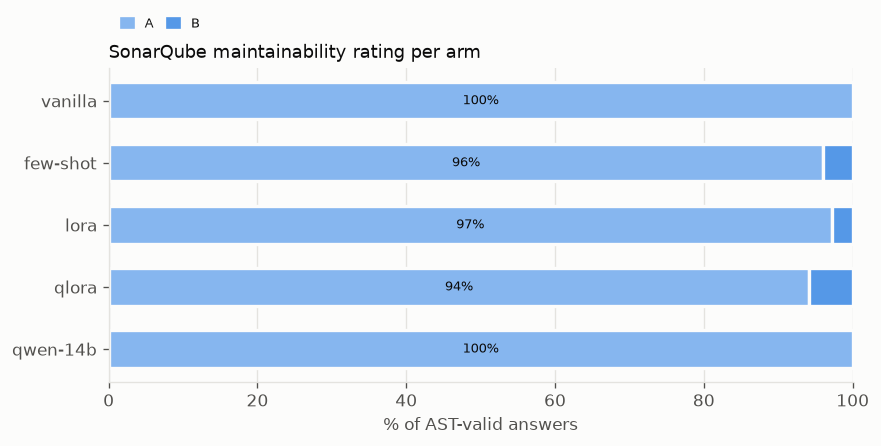

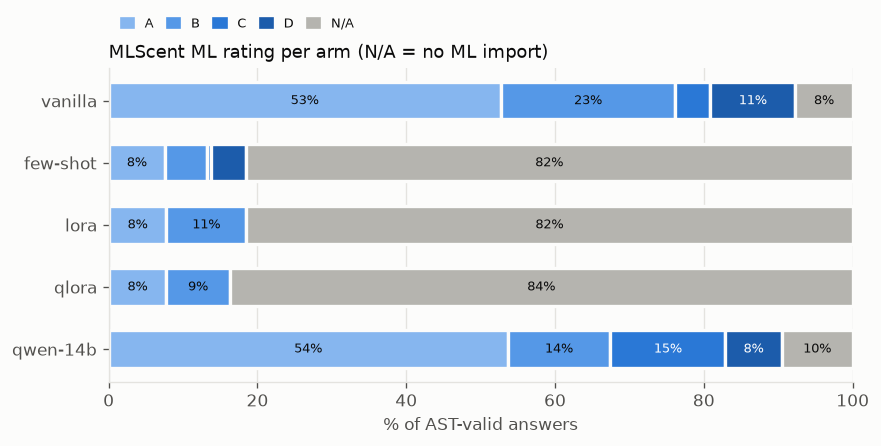

In [35]:
def grade_shares(column):
    """% of AST-valid answers per grade A-E, plus % not rated (N/A)."""
    rows = {}
    for arm in ARM_ORDER:
        values = pooled(arm).loc[lambda df: df["ast_valid"], column]
        rows[arm] = [100 * (values == g).mean() for g in range(1, 6)] + [100 * values.isna().mean()]
    return pd.DataFrame(rows, index=list("ABCDE") + ["N/A"]).T


def stacked_bars(shares, title):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    colors = GRADE_COLORS + [NA_COLOR]
    for y, arm in enumerate(shares.index):
        left = 0.0
        for (label, value), color in zip(shares.loc[arm].items(), colors):
            if value <= 0:
                continue
            ax.barh(y, value, left=left, height=0.6, color=color, edgecolor=SURFACE, linewidth=2)
            if value >= 7:
                dark = color in GRADE_COLORS[2:]
                ax.text(left + value / 2, y, f"{value:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if dark else INK)
            left += value
    ax.set_yticks(range(len(shares)), shares.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of AST-valid answers")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11)
    present = [(label, color) for label, color in zip(shares.columns, colors) if shares[label].sum() > 0]
    handles = [plt.Rectangle((0, 0), 1, 1, color=color) for _, color in present]
    ax.legend(handles, [label for label, _ in present], ncol=6, frameon=False, loc="lower left",
              bbox_to_anchor=(0, 1.08), fontsize=8, handlelength=1, columnspacing=1)
    plt.show()


stacked_bars(grade_shares("maintainability"), "SonarQube maintainability rating per arm")
stacked_bars(grade_shares("mlscent_ml_rating"), "MLScent ML rating per arm (N/A = no ML import)")

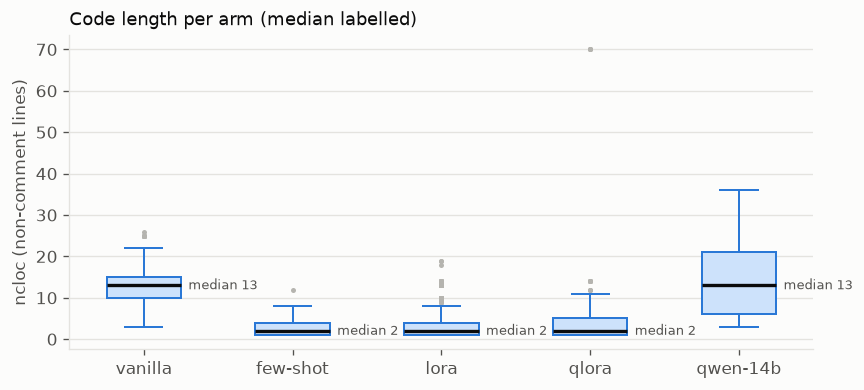

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.4))
data = [pooled(arm)["ncloc"].dropna() for arm in ARM_ORDER]
ax.boxplot(data, tick_labels=ARM_ORDER, widths=0.5, patch_artist=True, showfliers=True,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BAR, "linewidth": 1.2},
           whiskerprops={"color": BAR, "linewidth": 1.2}, capprops={"color": BAR, "linewidth": 1.2},
           medianprops={"color": INK, "linewidth": 2},
           flierprops={"marker": "o", "markersize": 3, "markerfacecolor": NA_COLOR, "markeredgecolor": "none"})
for x, values in enumerate(data, 1):
    ax.text(x + 0.3, values.median(), f"median {values.median():.0f}", va="center", ha="left", fontsize=8, color=INK_2)
ax.set_ylabel("ncloc (non-comment lines)")
ax.grid(axis="x", visible=False)
ax.set_title("Code length per arm (median labelled)", loc="left", fontsize=11)
plt.show()

### 3.2 Friedman (vanilla, few-shot, LoRA, QLoRA) → Wilcoxon + Holm (5 comparisons)

Post-hoc only when the omnibus test is significant. Primary = SonarQube metrics, secondary = MLScent rating.

In [37]:
def structural_tests(metrics):
    for metric in metrics:
        omnibus = friedman(tables[metric], FRIEDMAN_ARMS)
        print(f"\n=== {metric} | Friedman n={omnibus['n']} chi2={omnibus['chi2']:.3f} p={omnibus['p']:.4g} "
              f"Kendall's W={omnibus['kendall_w']:.3f}")
        if omnibus["p"] < ALPHA:
            display(wilcoxon_family(tables[metric], MAIN_FAMILY).round(4))
        else:
            print("not significant: no post-hoc")


structural_tests(PRIMARY + SECONDARY)


=== maintainability | Friedman n=274 chi2=33.324 p=2.751e-07 Kendall's W=0.041


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,274,0.0,0.0438,0.0005,1.0,0.0024,True
1,qlora − vanilla,277,0.0,0.0397,0.0010,1.0,0.0039,True
2,lora − few-shot,280,0.0,0.0000,1.0000,0.0,1.0000,False
3,qlora − few-shot,283,0.0,-0.0035,1.0000,-1.0,1.0000,False
4,lora − qlora,280,0.0,0.0036,1.0000,1.0,1.0000,False



=== code_smells | Friedman n=274 chi2=58.660 p=1.136e-12 Kendall's W=0.071


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,274,0.0,-0.0584,0.0350,-0.3094,0.0700,False
1,qlora − vanilla,277,0.0,-0.0614,0.0215,-0.3488,0.0645,False
2,lora − few-shot,280,0.0,0.2179,0.0000,0.9873,0.0000,True
3,qlora − few-shot,283,0.0,0.2120,0.0000,1.0000,0.0000,True
4,lora − qlora,280,0.0,0.0036,1.0000,0.3333,1.0000,False



=== complexity | Friedman n=274 chi2=50.923 p=5.08e-11 Kendall's W=0.062


...


=== cognitive_complexity | Friedman n=274 chi2=42.565 p=3.044e-09 Kendall's W=0.052


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,274,0.0,-0.1423,0.0001,-1.0000,0.0003,True
1,qlora − vanilla,277,0.0,-0.1264,0.0012,-0.7246,0.0049,True
2,lora − few-shot,280,0.0,-0.0214,0.0312,-1.0000,0.0938,False
3,qlora − few-shot,283,0.0,-0.0071,0.7539,-0.2000,0.7539,False
4,lora − qlora,280,0.0,-0.0143,0.1250,-1.0000,0.2500,False



=== bugs | Friedman n=274 chi2=nan p=nan Kendall's W=nan
not significant: no post-hoc

=== mlscent_ml_rating | Friedman n=6 chi2=8.769 p=0.03252 Kendall's W=0.487


/Users/dimasmaulana/.venvs/mlx/lib/python3.14/site-packages/scipy/stats/_stats_py.py:8776: RuntimeWarning: invalid value encountered in scalar divide
  statistic = (12.0 / (k*count*(k+1)) * ssbn - 3*count*(k+1)) / c


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,16,0.0,-0.4375,0.0625,-1.0,0.2500,False
1,qlora − vanilla,17,0.0,-0.6471,0.0312,-1.0,0.1562,False
2,lora − few-shot,6,-0.5,-0.5000,0.2500,-1.0,0.7500,False
3,qlora − few-shot,6,-0.5,-0.8333,0.2500,-1.0,0.7500,False
4,lora − qlora,16,0.0,0.1250,0.5000,1.0,0.7500,False


### 3.3 Sensitivity: the same tests on density per 100 `ncloc`

In [38]:
structural_tests(DENSITY)


=== code_smells_per_100_ncloc | Friedman n=274 chi2=45.053 p=9.014e-10 Kendall's W=0.055


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,274,0.0,3.0569,0.000,0.6464,0.000,True
1,qlora − vanilla,277,0.0,2.8454,0.000,0.6421,0.000,True
2,lora − few-shot,280,0.0,3.1080,0.000,0.9968,0.000,True
3,qlora − few-shot,283,0.0,2.9005,0.000,0.8857,0.000,True
4,lora − qlora,280,0.0,0.1764,0.625,0.4000,0.625,False



=== ml_findings_per_100_ncloc | Friedman n=6 chi2=7.552 p=0.05624 Kendall's W=0.420
not significant: no post-hoc


### 3.4 Qwen2.5-Coder-14B family (14B vs LoRA, QLoRA, vanilla 7B; own Holm correction)

In [39]:
for metric in PRIMARY + SECONDARY + DENSITY:
    print(f"\n=== {metric}")
    display(wilcoxon_family(tables[metric], FAMILY_14B).round(4))


=== maintainability


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,280,0.0,-0.0429,0.0005,-1.0,0.0015,True
1,qwen-14b − qlora,283,0.0,-0.0389,0.0010,-1.0,0.0020,True
2,qwen-14b − vanilla,298,0.0,0.0000,1.0000,0.0,1.0000,False



=== code_smells


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,280,0.0,-0.0929,0.0218,-0.2732,0.0436,True
1,qwen-14b − qlora,283,0.0,-0.0883,0.0234,-0.2751,0.0436,True
2,qwen-14b − vanilla,298,0.0,-0.1409,0.0000,-0.6364,0.0001,True



=== complexity


...

,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,16,1.0,0.7500,0.0137,0.7582,0.0273,True
1,qwen-14b − qlora,17,1.0,0.9412,0.0005,1.0000,0.0015,True
2,qwen-14b − vanilla,275,0.0,0.0182,0.6691,0.0454,0.6691,False



=== code_smells_per_100_ncloc


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,280,0.0,-4.0109,0.0000,-0.5376,0.0000,True
1,qwen-14b − qlora,283,0.0,-3.7939,0.0000,-0.5382,0.0000,True
2,qwen-14b − vanilla,298,0.0,-0.9580,0.0001,-0.5665,0.0001,True



=== ml_findings_per_100_ncloc


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,16,9.0909,5.2813,0.0720,0.5385,0.1440,False
1,qwen-14b − qlora,17,9.0909,7.5337,0.0005,1.0000,0.0015,True
2,qwen-14b − vanilla,275,0.0000,0.9258,0.0973,0.1558,0.1440,False


## 4. Functional correctness (RQ3, RQ4 baseline)

Binary result per problem: **Pass@1 = the first sample (sample 0) passes; Pass@10 = at least one of the 10 samples
passes.** LoRA/QLoRA: median (majority) of the 3 seeds. The unbiased pass@k estimates from `summary.json` are reported
descriptively.

In [40]:
def ds1000_binary(run):
    res = pd.read_json(get(f"{run}/ds1000_results.jsonl"), lines=True)
    first = res[res["sample"] == 0].set_index("problem_id")["passed"].astype(float)
    any_pass = res.groupby("problem_id")["passed"].any().astype(float)
    return pd.DataFrame({"pass1": first, "pass10": any_pass})


binary = {run: ds1000_binary(run) for runs in RUNS.values() for run in runs}
arm_binary = per_arm(binary, lambda df: df.round())          # median of three 0/1 values = majority
pass_tables = {k: pd.DataFrame({arm: df[k] for arm, df in arm_binary.items()}) for k in ("pass1", "pass10")}

summaries = {run: json.load(open(get(f"{run}/summary.json"))) for runs in RUNS.values() for run in runs}
functional = pd.DataFrame([{"arm": arm,
                            "pass@1 (unbiased, mean of seeds)": np.mean([summaries[r]["ds1000"]["pass@1"] for r in runs]),
                            "pass@10 (unbiased, mean of seeds)": np.mean([summaries[r]["ds1000"]["pass@10"] for r in runs]),
                            "pass1 binary rate": pass_tables["pass1"][arm].mean(),
                            "pass10 binary rate": pass_tables["pass10"][arm].mean()} for arm, runs in RUNS.items()])
functional.set_index("arm").round(4)

,"pass@1 (unbiased, mean of seeds)","pass@10 (unbiased, mean of seeds)",pass1 binary rate,pass10 binary rate
arm,,,,
vanilla,0.3634,0.6620,0.3721,0.6620
few-shot,0.4470,0.6680,0.4393,0.6680
qwen-14b,0.2757,0.5416,0.2798,0.5416
lora,0.3143,0.6138,0.3089,0.6128
qlora,0.3159,0.6185,0.3039,0.6118


In [41]:
# Seed variation (descriptive only)
pd.DataFrame([{"run": run, "pass@1": summaries[run]["ds1000"]["pass@1"], "pass@10": summaries[run]["ds1000"]["pass@10"]}
              for arm in ("lora", "qlora") for run in RUNS[arm]]).set_index("run").round(4)

,pass@1,pass@10
run,,
lora/seed-42,0.3168,0.6179
lora/seed-43,0.3086,0.6058
lora/seed-44,0.3175,0.6179
qlora/seed-42,0.3158,0.6229
qlora/seed-43,0.3152,0.6138
qlora/seed-44,0.3166,0.6189


#### Figure: Pass@1 and Pass@10 per arm

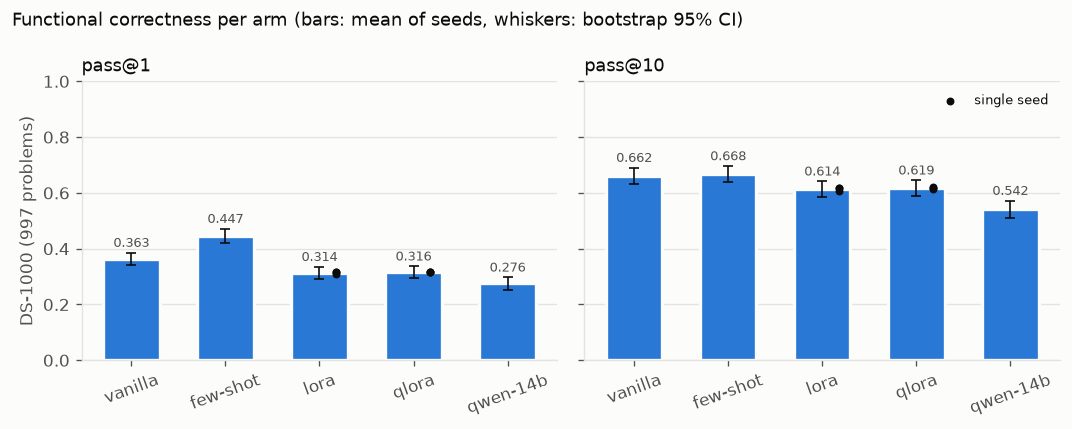

In [42]:
per_problem = {run: pd.DataFrame(json.load(open(get(f"{run}/ds1000_per_problem.json")))).T.astype(float)
               for runs in RUNS.values() for run in runs}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, k in zip(axes, ("pass@1", "pass@10")):
    for x, arm in enumerate(ARM_ORDER):
        runs = RUNS[arm]
        per_arm_problem = pd.concat([per_problem[r][k] for r in runs], axis=1).mean(axis=1)   # mean of seeds
        value = per_arm_problem.mean()
        low, high = bootstrap_ci(per_arm_problem)
        ax.bar(x, value, width=0.6, color=BAR, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(x, value, yerr=[[value - low], [high - value]], color=INK, capsize=3, linewidth=1)
        if len(runs) > 1:
            seeds = [summaries[r]["ds1000"][k] for r in runs]
            ax.scatter([x + 0.18] * len(seeds), seeds, s=14, color=INK, zorder=3, label="single seed" if x == 2 else None)
        ax.text(x, high + 0.02, f"{value:.3f}", ha="center", fontsize=8, color=INK_2)
    ax.set_xticks(range(len(ARM_ORDER)), ARM_ORDER, rotation=20)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_title(k, loc="left", fontsize=11)
axes[0].set_ylabel("DS-1000 (997 problems)")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Functional correctness per arm (bars: mean of seeds, whiskers: bootstrap 95% CI)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

### 4.1 Cochran's Q (vanilla, few-shot, LoRA, QLoRA) → McNemar + Holm (5 comparisons), paired bootstrap CI

In [43]:
for k in ("pass1", "pass10"):
    block = pass_tables[k][FRIEDMAN_ARMS].dropna()
    q = cochrans_q(block.to_numpy())
    print(f"\n=== {k} | Cochran's Q n={len(block)} Q={q.statistic:.3f} p={q.pvalue:.4g}")
    if q.pvalue < ALPHA:
        display(mcnemar_family(pass_tables[k], MAIN_FAMILY).round(4))
    else:
        print("not significant: no post-hoc")


=== pass1 | Cochran's Q n=997 Q=113.398 p=2.037e-24


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora − vanilla,997,0.3089,0.3721,-0.0632,-0.0923,-0.0341,83,146,0.00,0.0001,True
1,qlora − vanilla,997,0.3039,0.3721,-0.0682,-0.0983,-0.0371,90,158,0.00,0.0001,True
2,lora − few-shot,997,0.3089,0.4393,-0.1304,-0.1585,-0.1013,53,183,0.00,0.0000,True
3,qlora − few-shot,997,0.3039,0.4393,-0.1354,-0.1655,-0.1063,53,188,0.00,0.0000,True
4,lora − qlora,997,0.3089,0.3039,0.0050,-0.0120,0.0221,39,34,0.64,0.6400,False



=== pass10 | Cochran's Q n=997 Q=35.161 p=1.127e-07


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora − vanilla,997,0.6128,0.6620,-0.0491,-0.0752,-0.0231,66,115,0.0003,0.0007,True
1,qlora − vanilla,997,0.6118,0.6620,-0.0502,-0.0752,-0.0251,60,110,0.0002,0.0005,True
2,lora − few-shot,997,0.6128,0.6680,-0.0552,-0.0812,-0.0291,63,118,0.0001,0.0002,True
3,qlora − few-shot,997,0.6118,0.6680,-0.0562,-0.0822,-0.0301,63,119,0.0000,0.0002,True
4,lora − qlora,997,0.6128,0.6118,0.0010,-0.0160,0.0181,38,37,1.0000,1.0000,False


### 4.2 Qwen2.5-Coder-14B family (own Holm correction)

In [44]:
for k in ("pass1", "pass10"):
    print(f"\n=== {k}")
    display(mcnemar_family(pass_tables[k], FAMILY_14B).round(4))


=== pass1


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-14b − lora,997,0.2798,0.3089,-0.0291,-0.0612,0.0030,120,149,0.0876,0.1752,False
1,qwen-14b − qlora,997,0.2798,0.3039,-0.0241,-0.0572,0.0080,124,148,0.1630,0.1752,False
2,qwen-14b − vanilla,997,0.2798,0.3721,-0.0923,-0.1214,-0.0622,73,165,0.0000,0.0000,True



=== pass10


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-14b − lora,997,0.5416,0.6128,-0.0712,-0.1043,-0.0381,105,176,0.0,0.0001,True
1,qwen-14b − qlora,997,0.5416,0.6118,-0.0702,-0.1033,-0.0381,109,179,0.0,0.0001,True
2,qwen-14b − vanilla,997,0.5416,0.6620,-0.1204,-0.1515,-0.0893,72,192,0.0,0.0000,True


## 5. Trade-off structural vs functional (RQ2)

Arm-level only (structural on Code4ML, functional on DS-1000, so no per-sample correlation): is the arm with the best
structural quality also the arm with the best functional correctness? Rank 1 = best (lowest mean rating, highest pass@k).

In [45]:
tradeoff = pd.DataFrame({
    "mean_maintainability": descriptive["mean_maintainability"],
    "mean_mlscent_ml_rating": descriptive["mean_mlscent_ml_rating"],
    "pass@1": functional.set_index("arm")["pass@1 (unbiased, mean of seeds)"],
    "pass@10": functional.set_index("arm")["pass@10 (unbiased, mean of seeds)"],
})
tradeoff["rank_maintainability"] = tradeoff["mean_maintainability"].rank()
tradeoff["rank_mlscent"] = tradeoff["mean_mlscent_ml_rating"].rank()
tradeoff["rank_pass@1"] = tradeoff["pass@1"].rank(ascending=False)
for column in ("mean_maintainability", "mean_mlscent_ml_rating", "pass@1", "pass@10"):
    tradeoff[f"Δ {column} vs vanilla"] = tradeoff[column] - tradeoff.loc["vanilla", column]
print("best structural (maintainability):", tradeoff["mean_maintainability"].idxmin(),
      "| best functional (pass@1):", tradeoff["pass@1"].idxmax())
tradeoff.round(4)

best structural (maintainability): vanilla | best functional (pass@1): few-shot


,mean_maintainability,mean_mlscent_ml_rating,pass@1,pass@10,rank_maintainability,rank_mlscent,rank_pass@1,Δ mean_maintainability vs vanilla,Δ mean_mlscent_ml_rating vs vanilla,Δ pass@1 vs vanilla,Δ pass@10 vs vanilla
vanilla,1.0000,1.7273,0.3634,0.6620,1.5,3.0,2.0,0.0000,0.0000,0.0000,0.0000
few-shot,1.0395,2.1250,0.4470,0.6680,4.0,5.0,1.0,0.0395,0.3977,0.0837,0.0060
qwen-14b,1.0000,1.7455,0.2757,0.5416,1.5,4.0,5.0,0.0000,0.0182,-0.0877,-0.1204
lora,1.0429,1.1250,0.3143,0.6138,5.0,2.0,4.0,0.0429,-0.6023,-0.0491,-0.0481
qlora,1.0389,1.0000,0.3159,0.6185,3.0,1.0,3.0,0.0389,-0.7273,-0.0475,-0.0435


#### Figure: structural quality vs functional correctness

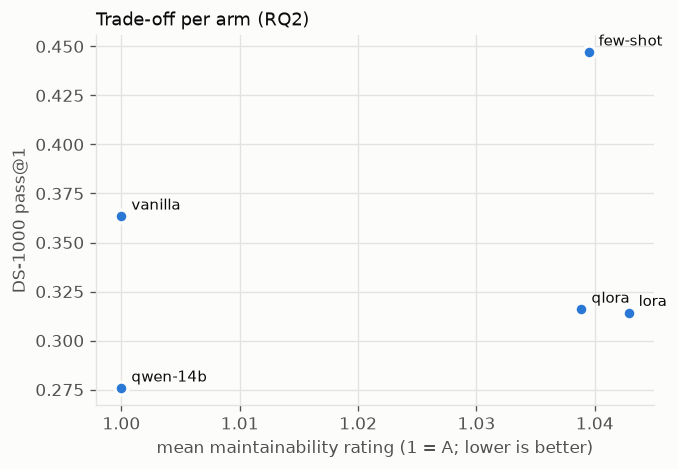

In [46]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(tradeoff["mean_maintainability"], tradeoff["pass@1"], s=60, color=BAR, edgecolor=SURFACE, linewidth=2, zorder=3)
for arm, row in tradeoff.iterrows():
    ax.annotate(arm, (row["mean_maintainability"], row["pass@1"]), xytext=(6, 4), textcoords="offset points",
                fontsize=9, color=INK)
ax.set_xlabel("mean maintainability rating (1 = A; lower is better)")
ax.set_ylabel("DS-1000 pass@1")
ax.set_title("Trade-off per arm (RQ2)", loc="left", fontsize=11)
plt.show()

## 6. Iterative refinement (RQ4)

Each iteration is a repeated measurement on the same problems: solved by iteration *i* (cumulative, greedy decoding).
Cochran's Q over iterations, then McNemar between consecutive iterations with Holm. **Saturation** = the first iteration
whose gain over the previous one is not significant after Holm **and** whose bootstrap 95% CI includes zero.
Structural (SonarQube) feedback was not run, so its exploratory part of RQ4 has no data here.

In [47]:
def refinement(method):
    summary_path = next(f for f in sorted(files) if f.startswith(f"refinement-{method}/") and f.endswith("summary.json"))
    summary = json.load(open(get(summary_path)))
    rows = pd.read_json(get(summary_path.replace("summary.json", "refinement_results.jsonl")), lines=True)
    first_pass = rows[rows["passed"]].groupby("problem_id")["iteration"].min()
    iterations = range(summary["max_iterations"] + 1)
    solved = pd.DataFrame({i: [float(first_pass.get(pid, np.inf) <= i) for pid in summary["problem_ids"]] for i in iterations},
                          index=summary["problem_ids"])
    q = cochrans_q(solved.to_numpy())
    print(f"\n=== refinement-{method} (seed {summary['seed']}, {len(solved)} problems) | "
          f"solved rate by iteration {[round(x, 4) for x in solved.mean()]} | Cochran's Q={q.statistic:.3f} p={q.pvalue:.4g}")
    steps = []
    for i in list(iterations)[1:]:
        gained = int(((solved[i] == 1) & (solved[i - 1] == 0)).sum())
        lost = int(((solved[i] == 0) & (solved[i - 1] == 1)).sum())
        both = int(((solved[i] == 1) & (solved[i - 1] == 1)).sum())
        p = mcnemar([[both, gained], [lost, len(solved) - both - gained - lost]], exact=True).pvalue
        low, high = bootstrap_ci(solved[i] - solved[i - 1])
        steps.append({"step": f"{i - 1}→{i}", "gain": (solved[i] - solved[i - 1]).mean(), "newly_solved": gained,
                      "ci95_low": low, "ci95_high": high, "p": p})
    steps = pd.DataFrame(steps)
    steps["p_holm"] = holm(steps["p"])
    steps["saturated"] = (steps["p_holm"] >= ALPHA) & (steps["ci95_low"] <= 0) & (steps["ci95_high"] >= 0)
    display(steps.round(4))
    first = steps[steps["saturated"]]
    saturation = int(first.iloc[0]["step"].split("→")[1]) if len(first) else None
    print("saturation point:", f"iteration {saturation}" if saturation is not None else "not reached within the loop")
    return {"rates": solved.mean().tolist(), "saturation": saturation}


refinement_results = {method: refinement(method) for method in ("lora", "qlora")}


=== refinement-lora (seed 42, 200 problems) | solved rate by iteration [0.415, 0.445, 0.45, 0.455] | Cochran's Q=18.600 p=0.0003307


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.030,6,0.01,0.055,0.0312,0.0938,False
1,1→2,0.005,1,0.00,0.015,1.0000,1.0000,True
2,2→3,0.005,1,0.00,0.015,1.0000,1.0000,True


saturation point: iteration 2

=== refinement-qlora (seed 42, 200 problems) | solved rate by iteration [0.415, 0.445, 0.46, 0.465] | Cochran's Q=22.091 p=6.245e-05


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.030,6,0.01,0.055,0.0312,0.0938,False
1,1→2,0.015,3,0.00,0.035,0.2500,0.5000,True
2,2→3,0.005,1,0.00,0.015,1.0000,1.0000,True


saturation point: iteration 2


#### Figure: refinement curve

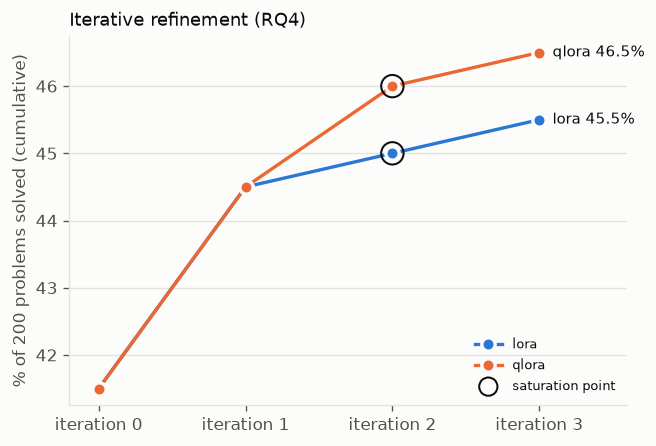

In [48]:
fig, ax = plt.subplots(figsize=(6, 4))
for method, result in refinement_results.items():
    rates = [100 * r for r in result["rates"]]
    its = range(len(rates))
    ax.plot(its, rates, color=LINE[method], linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=method)
    ax.annotate(f"{method} {rates[-1]:.1f}%", (its[-1], rates[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
    if result["saturation"] is not None:
        s = result["saturation"]
        ax.scatter(s, rates[s], s=180, facecolors="none", edgecolors=INK, linewidth=1.2, zorder=4)
ax.scatter([], [], s=120, facecolors="none", edgecolors=INK, linewidth=1.2, label="saturation point")
ax.set_xticks(range(len(rates)), [f"iteration {i}" for i in range(len(rates))])
ax.set_xlim(-0.2, len(rates) - 0.4)
ax.set_ylabel("% of 200 problems solved (cumulative)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Iterative refinement (RQ4)", loc="left", fontsize=11)
plt.show()